# MSci Project Test 1
We start with MGD-1K the meibography image dataset

Remember the main focus is on explainability and interpretability but there is some freedom as to where we take this project.




## Imports
We make use of multiple libraries for our project.

In [1]:
import os
os.environ['TF_GPU_ALLOCATOR'] = 'cuda_malloc_async' # helps with out of memory issues
import numpy as np
from numpy import save, load
import matplotlib.pyplot as plt
import random
from sklearn.metrics import confusion_matrix, precision_score, recall_score, classification_report
from sklearn.utils import class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import CSVLogger
from tensorflow.keras.applications import ResNet50, ResNet50V2
from tensorflow.keras.callbacks import ReduceLROnPlateau
from tensorflow.keras.applications import EfficientNetV2B0
from tensorflow.keras.models import load_model

import pandas as pd

import seaborn as sns

#from PIL import Image

2026-11-10 23:55:35.580457: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
## MSci project GPU settings

# Enable Memory Growth 
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory growth enabled")
    except RuntimeError as e:
        print(f"Memory growth error: {e}")
        
        
!nvidia-smi
tf.config.list_physical_devices('GPU')
tf.__version__


Memory growth enabled
Tue Nov 10 23:55:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3060        Off |   00000000:26:00.0  On |                  N/A |
| 64%   46C    P5             20W /  170W |    1082MiB /  12288MiB |      5%      Default |
|                                         |                        |                  N/A |
+-------------------------

'2.20.0'

# Data preprocessing


## Extract data with pandas 
Use Pandas to extract data (previously we tried os functions to get paths and directories)
So below we work with pandas and data frames instead, since we are already given the file names in the correct order. 

In [3]:
# using pandas load the main large excel file with 1000 images and multiple scores and final ground truth
main_df = pd.read_excel('/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Graded Meiboscore/6 Round Meiboscore by MGD Experts.xlsx')
# using pandas load the csv file for the testing dataset
test_only_df = pd.read_csv('/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Graded Meiboscore/200 test Images used for Meiboscore Classification.txt',
                           sep = " ", header = None) # our file names have no spaces so sep=" " is okay

print("main_df ", main_df.shape)
print("test_only_df shape is ", test_only_df.shape)

main_df  (1000, 9)
test_only_df shape is  (200, 1)


In [4]:
# For our main data frame
filenames = main_df.iloc[:, 1].values # gets all the filenames in the same order as the excel file
labels = main_df.iloc[:, 8].values # gets all the labels or ground truth values in the same order as the excel file

# We print the first 5 and double check the filename corresponds to the labels from our data(from the excel file)
print(filenames[0:5])
print(filenames.shape)
print(labels[0:5]) 


# For our test data frame
## Convert test data frame into list of filenames
test_filenames =  test_only_df.iloc[:, 0].values

print(test_filenames[0:5])
print(test_filenames.shape) # shows that is it a 2d numpy array (200 rows, 1 column)

test_list = test_filenames.tolist() # convert to list
print(test_list[0:5])
print("Length of test_list is:", len(test_list))

['DMI_OD_UPPER_REFLECTED_IR_22393213.png'
 'DMI_OD_UPPER_REFLECTED_IR_22912884.png'
 'DMI_OD_UPPER_REFLECTED_IR_23043359.png'
 'DMI_OS_LOWER_REFLECTED_IR_8958472.png'
 'DMI_OS_LOWER_REFLECTED_IR_12613265.png']
(1000,)
[2 0 0 1 1]
['DMI_OD_LOWER_REFLECTED_IR_10248573.png'
 'DMI_OD_LOWER_REFLECTED_IR_10408283.png'
 'DMI_OD_LOWER_REFLECTED_IR_10441395.png'
 'DMI_OD_LOWER_REFLECTED_IR_10847668.png'
 'DMI_OD_LOWER_REFLECTED_IR_10988503.png']
(200,)
['DMI_OD_LOWER_REFLECTED_IR_10248573.png', 'DMI_OD_LOWER_REFLECTED_IR_10408283.png', 'DMI_OD_LOWER_REFLECTED_IR_10441395.png', 'DMI_OD_LOWER_REFLECTED_IR_10847668.png', 'DMI_OD_LOWER_REFLECTED_IR_10988503.png']
Length of test_list is: 200


In [5]:
# Filtering into training and testing datasets (dataframes)
#main_df is excel file and index 1 is the filename column)
train_df = main_df[~main_df.iloc[:, 1].isin(test_list)]
test_df = main_df[main_df.iloc[:, 1].isin(test_list)]
print(train_df)
print(test_df)

       No                                    name  O1R1  O1R2  O1R3  O2R1  \
0       1  DMI_OD_UPPER_REFLECTED_IR_22393213.png   1.0   2.0   1.0   2.0   
1       2  DMI_OD_UPPER_REFLECTED_IR_22912884.png   0.0   0.0   0.0   1.0   
2       3  DMI_OD_UPPER_REFLECTED_IR_23043359.png   0.0   1.0   0.0   1.0   
3       4   DMI_OS_LOWER_REFLECTED_IR_8958472.png   1.0   1.0   1.0   1.0   
4       5  DMI_OS_LOWER_REFLECTED_IR_12613265.png   1.0   1.0   1.0   1.0   
..    ...                                     ...   ...   ...   ...   ...   
994   995   DMI_OD_UPPER_REFLECTED_IR_8911190.png   0.0   0.0   0.0   0.0   
996   997  DMI_OD_UPPER_REFLECTED_IR_16807525.png   2.0   1.0   2.0   2.0   
997   998  DMI_OD_UPPER_REFLECTED_IR_18864247.png   1.0   1.0   1.0   1.0   
998   999  DMI_OD_UPPER_REFLECTED_IR_20589332.png   1.0   0.0   0.0   1.0   
999  1000  DMI_OD_UPPER_REFLECTED_IR_22262504.png   1.0   1.0   1.0   2.0   

     O2R2  O2R3  Ground Truth  
0     2.0   3.0             2  
1     1.0  

In [6]:
print(train_df[0:7]) # see how empty values from our excel are reported as "NaN"

   No                                    name  O1R1  O1R2  O1R3  O2R1  O2R2  \
0   1  DMI_OD_UPPER_REFLECTED_IR_22393213.png   1.0   2.0   1.0   2.0   2.0   
1   2  DMI_OD_UPPER_REFLECTED_IR_22912884.png   0.0   0.0   0.0   1.0   1.0   
2   3  DMI_OD_UPPER_REFLECTED_IR_23043359.png   0.0   1.0   0.0   1.0   0.0   
3   4   DMI_OS_LOWER_REFLECTED_IR_8958472.png   1.0   1.0   1.0   1.0   1.0   
4   5  DMI_OS_LOWER_REFLECTED_IR_12613265.png   1.0   1.0   1.0   1.0   1.0   
5   6  DMI_OS_LOWER_REFLECTED_IR_14926151.png   1.0   1.0   0.0   2.0   2.0   
6   7  DMI_OS_LOWER_REFLECTED_IR_17696458.png   1.0   NaN   1.0   1.0   1.0   

   O2R3  Ground Truth  
0   3.0             2  
1   0.0             0  
2   0.0             0  
3   1.0             1  
4   1.0             1  
5   1.0             1  
6   1.0             1  


##  Remove NaN values
See above how empty values from our excel are reported as "NaN"

We need to filter NaN from both training and testing dataframes. Removes any row with at least one NaN.

In [7]:
train_df_cleaned = train_df.dropna()
test_df_cleaned = test_df.dropna()

print(train_df_cleaned)
print(test_df_cleaned)

       No                                    name  O1R1  O1R2  O1R3  O2R1  \
0       1  DMI_OD_UPPER_REFLECTED_IR_22393213.png   1.0   2.0   1.0   2.0   
1       2  DMI_OD_UPPER_REFLECTED_IR_22912884.png   0.0   0.0   0.0   1.0   
2       3  DMI_OD_UPPER_REFLECTED_IR_23043359.png   0.0   1.0   0.0   1.0   
3       4   DMI_OS_LOWER_REFLECTED_IR_8958472.png   1.0   1.0   1.0   1.0   
4       5  DMI_OS_LOWER_REFLECTED_IR_12613265.png   1.0   1.0   1.0   1.0   
..    ...                                     ...   ...   ...   ...   ...   
994   995   DMI_OD_UPPER_REFLECTED_IR_8911190.png   0.0   0.0   0.0   0.0   
996   997  DMI_OD_UPPER_REFLECTED_IR_16807525.png   2.0   1.0   2.0   2.0   
997   998  DMI_OD_UPPER_REFLECTED_IR_18864247.png   1.0   1.0   1.0   1.0   
998   999  DMI_OD_UPPER_REFLECTED_IR_20589332.png   1.0   0.0   0.0   1.0   
999  1000  DMI_OD_UPPER_REFLECTED_IR_22262504.png   1.0   1.0   1.0   2.0   

     O2R2  O2R3  Ground Truth  
0     2.0   3.0             2  
1     1.0  

After Removing not fully gradable images from training and testing dataset we see that we get what the original researchers from MGD1K got i.e the benchmark paper see the flowchart from their website they got 752 and 189 in their datasets respectively. We successfully reproduced this.

## Creating directories and paths

In [8]:
# For our training data frame
train_filenames = train_df_cleaned.iloc[:, 1].values # gets all the filenames in the same order as the excel file
train_labels = train_df_cleaned.iloc[:, 8].values # gets all the labels or ground truth values in the same order as the excel file

# We print the first 5 and double check the filename corresponds to the labels from our data(from the excel file)
print(train_filenames[0:5])
print(train_filenames.shape)
print(train_labels[0:5]) 


# For our testing data frame
test_filenames = test_df_cleaned.iloc[:, 1].values # gets all the filenames in the same order as the excel file
test_labels = test_df_cleaned.iloc[:, 8].values # gets all the labels or ground truth values in the same order as the excel file

# We print the first 5 and double check the filename corresponds to the labels from our data(from the excel file)
print(test_filenames[0:5])
print(test_filenames.shape)
print(test_labels[0:5]) 

['DMI_OD_UPPER_REFLECTED_IR_22393213.png'
 'DMI_OD_UPPER_REFLECTED_IR_22912884.png'
 'DMI_OD_UPPER_REFLECTED_IR_23043359.png'
 'DMI_OS_LOWER_REFLECTED_IR_8958472.png'
 'DMI_OS_LOWER_REFLECTED_IR_12613265.png']
(752,)
[2 0 0 1 1]
['DMI_OS_LOWER_REFLECTED_IR_22875501.png'
 'DMI_OD_LOWER_REFLECTED_IR_11411345.png'
 'DMI_OD_LOWER_REFLECTED_IR_16820410.png'
 'DMI_OD_LOWER_REFLECTED_IR_20867303.png'
 'DMI_OD_LOWER_REFLECTED_IR_22385966.png']
(189,)
[1 2 0 0 3]


We checked the ground truth labels match to the correct file name they do!

In [9]:
# Define folder path
image_folder = '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images'
image_folder_eyelid_masks = '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Eyelid Lebels'
image_folder_gland_masks = '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Meibomian Gland Labels'

# Convert our simple list of train_filenames into directories
train_file_paths = [os.path.join(image_folder, fname) for fname in train_filenames]
train_file_paths_eyelid_masks = [os.path.join(image_folder_eyelid_masks, fname) for fname in train_filenames]
train_file_paths_gland_masks = [os.path.join(image_folder_gland_masks, fname) for fname in train_filenames]


# Convert our simply list of test_filenames into directories
test_file_paths = [os.path.join(image_folder, fname) for fname in test_filenames]###
test_file_paths_eyelid_masks = [os.path.join(image_folder_eyelid_masks, fname) for fname in test_filenames]
test_file_paths_gland_masks = [os.path.join(image_folder_gland_masks, fname) for fname in test_filenames]

print(train_file_paths[0:5], "\n", len(train_file_paths))
print(test_file_paths[0:5], "\n", len(test_file_paths))

# Note that these print in the order according to os and not our predetermined order from the excel 
print(os.listdir(image_folder)[:5])

['/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OD_UPPER_REFLECTED_IR_22393213.png', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OD_UPPER_REFLECTED_IR_22912884.png', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OD_UPPER_REFLECTED_IR_23043359.png', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OS_LOWER_REFLECTED_IR_8958472.png', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OS_LOWER_REFLECTED_IR_12613265.png'] 
 752
['/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OS_LOWER_REFLECTED_IR_22875501.png', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OD_LOWER_REFLECTED_IR_11411345.png', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OD_LOWER_REFLECTED_IR_16820410.png', '

## Fix directories using .png to .jpg
Note how the directorys are .jpg but in the excel they have labelled as .png this is a mistake we can manually correct or we can fix with python.

This is only true for the original raw images. For the eyelid masks and the meibomian gland masks they are png so it is fine.

In [10]:
train_file_paths = [str(f).replace('.png', '.JPG') for f in train_file_paths]
test_file_paths = [str(f).replace('.png', '.JPG') for f in test_file_paths]

print(train_file_paths[0:5], "\n", len(train_file_paths))
print(test_file_paths[0:5], "\n", len(test_file_paths))

['/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OD_UPPER_REFLECTED_IR_22393213.JPG', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OD_UPPER_REFLECTED_IR_22912884.JPG', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OD_UPPER_REFLECTED_IR_23043359.JPG', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OS_LOWER_REFLECTED_IR_8958472.JPG', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OS_LOWER_REFLECTED_IR_12613265.JPG'] 
 752
['/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OS_LOWER_REFLECTED_IR_22875501.JPG', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OD_LOWER_REFLECTED_IR_11411345.JPG', '/home/howard/Downloads/MGD1k-main/MGD1k-main/Expore MGD1k Dataset/Original Images/DMI_OD_LOWER_REFLECTED_IR_16820410.JPG', '

## Create our dataset/split training dataset into training and validation

In [11]:
def load_and_preprocess(original_img_path, eyelid_mask_path, gland_mask_path, label):
    # Helper to load and decode specific formats
    def load_img(path, is_png=False):
        img = tf.io.read_file(path)
        if is_png:
            img = tf.image.decode_png(img, channels=1)
            img = tf.image.resize(img, [224, 448], method='nearest') # discrete 0 or 1 value for masks
            #img = tf.image.resize(img, [320, 640], method='nearest') # discrete 0 or 1 value for masks
        else:
            img = tf.image.decode_jpeg(img, channels=1)
            img = tf.image.resize(img, [224, 448], method='bilinear') # discrete 0 or 1 value for masks
            #img = tf.image.resize(img, [320, 640], method='bilinear') # discrete 0 or 1 value for masks
        return tf.cast(img, tf.float32) / 255.0        

    # Load each with the correct decoder
    original = load_img(original_img_path, is_png=False)
    eyelid   = load_img(eyelid_mask_path, is_png=True)
    gland    = load_img(gland_mask_path, is_png=True)

    # Apply the eyelid mask to the original image
    # This zeroes out everything outside the eyelid region for our original (image channel 1)
    masked_original = original * eyelid

    # Stack them into a 3-channel tensor (320, 640, 3)
    #combined_img = tf.concat([original, eyelid, gland], axis=-1)
    # to reset to include entire raw image set first argument to original instead of masked_original
    combined_img = tf.concat([masked_original, eyelid, gland], axis=-1) 
    
    return combined_img, label

# # halo to eyelid mask 
# def load_and_preprocess(original_img_path, eyelid_mask_path, gland_mask_path, label):
#     def load_img(path, is_png=False):
#         img = tf.io.read_file(path)
#         if is_png:
#             img = tf.image.decode_png(img, channels=1)
#             img = tf.image.resize(img, [224, 448], method='nearest')
#         else:
#             img = tf.image.decode_jpeg(img, channels=1)
#             img = tf.image.resize(img, [224, 448], method='bilinear')
#         return tf.cast(img, tf.float32) / 255.0

#     original = load_img(original_img_path, is_png=False)
#     eyelid   = load_img(eyelid_mask_path, is_png=True)
#     gland    = load_img(gland_mask_path, is_png=True)

#     # --- Create the Halo Mask ---
#     # 1. Expand dimensions to [Batch=1, Height, Width, Channel=1] for pooling
#     eyelid_4d = tf.expand_dims(eyelid, 0)
    
#     # 2. Apply Max Pooling to dilate the mask
#     # ksize and strides determine the size of the halo. 
#     # A 15x15 kernel creates a significant buffer.
#     halo_mask_4d = tf.nn.max_pool2d(
#         eyelid_4d, 
#         ksize=[1, 12, 12, 1], 
#         strides=[1, 1, 1, 1], 
#         padding='SAME'
#     )
    
#     # 3. Squeeze back to [224, 448, 1]
#     halo_mask = tf.squeeze(halo_mask_4d, axis=0)

#     # Apply the dilated halo mask instead of the tight eyelid mask
#     masked_original = original * halo_mask

#     # Stack: channel 0 is masked image, channel 1 is the original tight mask, channel 2 is gland
#     combined_img = tf.concat([masked_original, eyelid, gland], axis=-1) 
    
#     return combined_img, label

#######
## Create the dataset, we initially have a training and testing data set in 80:20 split, we split  the training set using the split ratio
## so the training set turns into a training and validation set
# 1. Define your split ratio
total_items = len(train_file_paths)
val_size = int(total_items * 0.15) 

# 2. "Glue" paths and labels together into one Dataset object
# This ensures that index 50 of paths always stays with index 50 of labels
full_dataset = tf.data.Dataset.from_tensor_slices((
    (train_file_paths, train_file_paths_eyelid_masks,train_file_paths_gland_masks),
                                                   train_labels))

# 3. Shuffle the pairs
# The buffer_size should be equal to the total number of items for a perfect shuffle
full_dataset = full_dataset.shuffle(buffer_size=total_items, seed=42, reshuffle_each_iteration=False)

# 4. Now split the zipped pairs
train_dataset = full_dataset.skip(val_size)
val_dataset = full_dataset.take(val_size)

# Since we have tuple array of paths to image we need to map those into actual images, we do this for both our train and val datasets
train_dataset = train_dataset.map(lambda paths, label: load_and_preprocess(paths[0], paths[1], paths[2], label),
                                  num_parallel_calls=tf.data.AUTOTUNE)
val_dataset = val_dataset.map(lambda paths, label: load_and_preprocess(paths[0], paths[1], paths[2], label),
                              num_parallel_calls=tf.data.AUTOTUNE)


# Use the predefined test dataset to create our test dataset, this is simple as we dont need to split the testing dataset, we leave as is
test_dataset = tf.data.Dataset.from_tensor_slices((
    (test_file_paths, test_file_paths_eyelid_masks, test_file_paths_gland_masks),
                                                   test_labels))
# As before we remap our tuple of paths into actual images
test_dataset = test_dataset.map(lambda paths, label: load_and_preprocess(paths[0], paths[1], paths[2], label),
                              num_parallel_calls=tf.data.AUTOTUNE)

#########################################################################################################

# # First, let's see what the raw dataset contains (without processing) , keep this commented out.
# for item in train_dataset.take(1):
#     print("Raw dataset structure:")
#     print("Type of item:", type(item))
#     print("Item structure:", item)
#     print("-" * 50)


for image, label in train_dataset.take(1):
    print("Image shape:", image.shape)
    print("Label shape:", label.shape)


I0000 00:00:1794354937.328416  586208 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1794354937.329791  586208 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9161 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:26:00.0, compute capability: 8.6


Image shape: (224, 448, 3)
Label shape: ()


2026-11-10 23:55:38.129379: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## Data augmentation

In [12]:
# Data augmentation
# 1. Initialize the rotation layer OUTSIDE the function
# This creates the variables only once.
rotation_layer = tf.keras.layers.RandomRotation(
    factor=0.027, # angle in degrees is x, factor = x/360
    #fill_mode='reflect'
    #fill_mode='nearest'    
    fill_mode='constant',
    fill_value=0.0
)

shift_layer = tf.keras.layers.RandomTranslation(
    height_factor=0.03, # Shift up/down by up to 3%
    width_factor=0.03,  # Shift left/right by up to 3%
    fill_mode='constant',
    fill_value=0.0
)

zoom_layer = tf.keras.layers.RandomZoom(
    height_factor=(-0.03, 0.03), # Zoom in or out by 3%
    width_factor=(-0.03, 0.03),
    fill_mode='constant',
    fill_value=0.0
)


# only applies brightness changes to first image and not masks
def augment_image(image, label):
    # 1. Split Channels: [H, W, 0] is image, [H, W, 1:3] are masks
    img_chan = image[:, :, :1]
    eyelid_mask = image[:, :, 1:2] # Channel 1 <--- Use this to "re-clean"
    mask_chans = image[:, :, 1:]

    # 2. Augment ONLY the image channel
    img_chan = tf.image.random_brightness(img_chan, max_delta=0.1)
    img_chan = tf.image.random_contrast(img_chan, lower=0.9, upper=1.1)

    # We generate noise with the same shape as the image channel
    NOISE_STDDEV = 0.02
    noise = tf.random.normal(shape=tf.shape(img_chan), mean=0.0, stddev=NOISE_STDDEV, dtype=tf.float32)
    img_chan = img_chan + noise
    
    
    # CRITICAL FIX: Clip the values back to [0, 1]
    img_chan = tf.clip_by_value(img_chan, clip_value_min=0.0, clip_value_max=1.0)

    # ROI METHOD: Get rid of positive noise, positive values outside the ROI, we apply mask to zero out that region
    img_chan = img_chan * eyelid_mask
    
    # 3. Recombine
    image = tf.concat([img_chan, mask_chans], axis=-1)

    # 4. Apply Spatial Augmentation to the WHOLE stack (Flip/Rotate)
    image = tf.image.random_flip_left_right(image)
    image = tf.expand_dims(image, 0)
    image = rotation_layer(image)
    image = shift_layer(image)  # Adds the small shifts
    image = zoom_layer(image)   # Adds the zoom in/out

    # Remove batch dimension
    image = tf.squeeze(image, 0)

    return image, label

# # halo to eyelid mask
# def augment_image(image, label):
#     # 1. Split Channels: [H, W, 0] is image, [H, W, 1:3] are masks
#     img_chan = image[:, :, :1]
#     eyelid_mask = image[:, :, 1:2] # Channel 1 <--- Use this to "re-clean"
#     mask_chans = image[:, :, 1:]

#     # 2. Augment ONLY the image channel
#     img_chan = tf.image.random_brightness(img_chan, max_delta=0.1)
#     img_chan = tf.image.random_contrast(img_chan, lower=0.9, upper=1.1)

#     # We generate noise with the same shape as the image channel
#     NOISE_STDDEV = 0.02
#     noise = tf.random.normal(shape=tf.shape(img_chan), mean=0.0, stddev=NOISE_STDDEV, dtype=tf.float32)
#     img_chan = img_chan + noise
    
    
#     # CRITICAL FIX: Clip the values back to [0, 1]
#     img_chan = tf.clip_by_value(img_chan, clip_value_min=0.0, clip_value_max=1.0)

#     # Get rid of positive noise, positive values outside the ROI, we apply mask to zero out that region
#     # --- Create the Halo Mask ---
#     # 1. Expand dimensions to [Batch=1, Height, Width, Channel=1] for pooling
#     eyelid_4d = tf.expand_dims(eyelid_mask, 0)

#     # 2. Apply Max Pooling to dilate the mask
#     # ksize and strides determine the size of the halo. 
#     # A 15x15 kernel creates a significant buffer.
#     halo_mask_4d = tf.nn.max_pool2d(
#     eyelid_4d, 
#     ksize=[1, 12, 12, 1], 
#     strides=[1, 1, 1, 1], 
#     padding='SAME'
#     )

#     # 3. Squeeze back to [224, 448, 1]
#     halo_mask = tf.squeeze(halo_mask_4d, axis=0)

#     # Apply the dilated halo mask instead of the tight eyelid mask
#     img_chan = img_chan * halo_mask
    
#     # 3. Recombine
#     image = tf.concat([img_chan, mask_chans], axis=-1)

#     # 4. Apply Spatial Augmentation to the WHOLE stack (Flip/Rotate)
#     image = tf.image.random_flip_left_right(image)
#     image = tf.expand_dims(image, 0)
#     image = rotation_layer(image)
#     image = shift_layer(image)  # Adds the small shifts
#     image = zoom_layer(image)   # Adds the zoom in/out

#     # Remove batch dimension
#     image = tf.squeeze(image, 0)

#     return image, label    

## Halo Data augmentation version

In [13]:
# # Data augmentation
# # 1. Initialize the rotation layer OUTSIDE the function
# # This creates the variables only once.
# rotation_layer = tf.keras.layers.RandomRotation(
#     factor=0.027, # angle in degrees is x, factor = x/360
#     #fill_mode='reflect'
#     #fill_mode='nearest'    
#     fill_mode='constant',
#     fill_value=0.0
# )

# shift_layer = tf.keras.layers.RandomTranslation(
#     height_factor=0.04, # Shift up/down by up to 3%
#     width_factor=0.04,  # Shift left/right by up to 3%
#     fill_mode='constant',
#     fill_value=0.0
# )

# zoom_layer = tf.keras.layers.RandomZoom(
#     height_factor=(-0.03, 0.03), # Zoom in or out by 3%
#     width_factor= None , # defaults to same as height if set to None, this is good otherwise its a random number so zoom in width could be different to zoom in height
#     fill_mode='constant',
#     fill_value=0.0
# )

# # halo to eyelid mask after rotation as halo before rotation means the edges at the halo when rotated generate bad info when interpolated
# def augment_image(image, label):
#     # 1. Intensity Augmentation (Brightness/Contrast/Noise)
#     # We do this while the image is still 3D
#     img_chan = image[:, :, :1]
#     mask_chans = image[:, :, 1:]

#     img_chan = tf.image.random_brightness(img_chan, max_delta=0.1)
#     img_chan = tf.image.random_contrast(img_chan, lower=0.9, upper=1.1)

#     noise = tf.random.normal(shape=tf.shape(img_chan), mean=0.0, stddev=0.02, dtype=tf.float32)
#     img_chan = tf.clip_by_value(img_chan + noise, 0.0, 1.0) # CRITICAL FIX: Clip the values back to [0, 1] (VERY IMPORTANT FOR CLIPPING INSIDE THE MASK)
    
#     # Recombine to apply spatial transforms to the whole stack
#     image = tf.concat([img_chan, mask_chans], axis=-1)
#     image = tf.image.random_flip_left_right(image)

#     # 2. Spatial Augmentation (Rotate/Shift/Zoom)
#     # These layers require a 4D tensor [Batch, H, W, C]
#     image = tf.expand_dims(image, 0)
#     image = rotation_layer(image)
#     image = shift_layer(image)
#     image = zoom_layer(image)

#     # 3. Squeeze back to 3D for processing
#     image_3d = tf.squeeze(image, axis=0)

#     # 4. Slice the Rotated Channels
#     img_rotated = image_3d[:, :, :1]
#     eyelid_rotated = image_3d[:, :, 1:2]
#     other_masks = image_3d[:, :, 2:]

#     # 5. Create the "Cookie Cutter" Halo Mask from rotated eyelid
#     # Reshape ensures we are strictly 4D for the MaxPool operation
#     eyelid_4d_for_pool = tf.reshape(eyelid_rotated, [1, 224, 448, 1])
    
#     halo_4d = tf.nn.max_pool2d(
#         eyelid_4d_for_pool, 
#         ksize=[1, 12, 12, 1], 
#         strides=[1, 1, 1, 1], 
#         padding='SAME'
#     )
    
#     halo_mask = tf.squeeze(halo_4d, axis=0)

#     # 6. Apply Halo Mask and Recombine
#     img_final = img_rotated * halo_mask
    
#     # This is your final 3-channel augmented image
#     image_final = tf.concat([img_final, eyelid_rotated, other_masks], axis=-1)

#     return image_final, label

## Upsampling minority classes

In [14]:
# --- STEP 1: LOAD & PREPROCESS (Base) ---
# We already have train_dataset and val_dataset mapped with load_and_preprocess.
# We add .cache() HERE. This saves the 224x448 resized images.
# If your RAM is still too full, use: .cache('/home/howard/train_cache')
train_dataset_cached = train_dataset.cache()
val_dataset_cached = val_dataset.cache()

# --- STEP 2: BALANCING (Using cached data) ---
# Isolate minority classes from the CACHED (un-augmented) data
val0_ds = train_dataset_cached.filter(lambda x, y: y == 0).take(30)
val2_ds = train_dataset_cached.filter(lambda x, y: y == 2).take(40)
val3_ds = train_dataset_cached.filter(lambda x, y: y == 3).repeat(6)

# Combine them
train_dataset_balanced = train_dataset_cached.concatenate(val0_ds).concatenate(val2_ds).concatenate(val3_ds)
train_dataset_balanced = train_dataset_balanced.cache()

## Batch size and actually applying augmentations and creating our dataset

In [15]:
batch_size=64

# --- STEP 3: AUGMENT, SHUFFLE, BATCH ---
# We apply augmentation AFTER balancing and caching.
# This ensures new random values every epoch.
train_dataset_for_model = (
    train_dataset_balanced
    .shuffle(buffer_size=1000) 
    .map(augment_image, num_parallel_calls=tf.data.AUTOTUNE) # Fresh augmentation
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset_for_model = (
    val_dataset_cached
    .batch(batch_size)
    .prefetch(tf.data.AUTOTUNE)
)

# Test doesn't need cache unless you run it multiple times, 
# but it doesn't hurt if you have RAM.
test_dataset_for_model = test_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

Image is as we expect for 1 sample image we have a image of certain width and height
label is a scalar hence empty

In [16]:
## helps to remove missing files, we previously created a model and trained the model which led to errors due to the missing files so we leave this here
## in memory of the missing files
for name, separate_paths in [("train_file_paths", train_file_paths), 
                             ("test_file_paths", test_file_paths),
                             ("train_file_paths_eyelid_masks", train_file_paths_eyelid_masks), 
                             ("test_file_paths_eyelid_masks", test_file_paths_eyelid_masks),
                             ("train_file_paths_gland_masks", train_file_paths_gland_masks),
                             ("test_file_paths_gland_masks", test_file_paths_gland_masks)]:
    missing_files = []
    for path in separate_paths:
        if not os.path.exists(path):
            missing_files.append(path)
            
    print(f"{name}")
    print(f"Total files in Excel: {len(separate_paths)}")
    print(f"Total missing from folder: {len(missing_files)}")
    
    if missing_files:
        print("\nFirst 3 missing files for you to check manually:")
        for f in missing_files[:3]:
            print(f" - {os.path.basename(f)}")
    
    print() # print a blank linkfor clarity


train_file_paths
Total files in Excel: 752
Total missing from folder: 0

test_file_paths
Total files in Excel: 189
Total missing from folder: 0

train_file_paths_eyelid_masks
Total files in Excel: 752
Total missing from folder: 0

test_file_paths_eyelid_masks
Total files in Excel: 189
Total missing from folder: 0

train_file_paths_gland_masks
Total files in Excel: 752
Total missing from folder: 0

test_file_paths_gland_masks
Total files in Excel: 189
Total missing from folder: 0



I searched for this in file explorer in the original images folder, it was labelled with .jpg instead of .JPG unlike the rest, since it was just one I fixed it manualy by renaming. Previously this code found 1 missing file for the dataset in training and no missing files in testing dataset.

## Quick checks of our dataset and check class imbalance

Random is set to 42 when shuffing the "full_dataset" and splitting into training and validation dataset. So if we restart the kernel we will get the same number occurences for each value for each dataset.

We also print the occurences of each class or value in each dataset to see class imbalance.


In [17]:
# Extract training labels as they are in a tf.data.Dataset objects when we create the datasets and shuffle.
# We map to 'label' (the second element, index 1) and then convert to numpy
train_labels_array = np.array(list(train_dataset.map(lambda path, label: label).as_numpy_iterator())) # numpy array of training labels

# Extract validation labels
val_labels_array = np.array(list(val_dataset.map(lambda path, label: label).as_numpy_iterator())) # numpy array of validation labels

print(f"Training labels shape: {train_labels_array.shape}")
print(f"Validation labels shape: {val_labels_array.shape}")
print(f"Test labels shape: {test_labels.shape}")
####

counts = np.bincount(train_labels_array)
print("For training set:")
for i in range(4):
    print(f"Value {i}: {counts[i]} occurrences")

counts = np.bincount(val_labels_array)
print("For validation set:")
for i in range(4):
    print(f"Value {i}: {counts[i]} occurrences")

# test dataset, count occurence of each label (meiboscore)
counts = np.bincount(test_labels)
print("For testing set:")
for i in range(4):
    print(f"Value {i}: {counts[i]} occurrences")

Training labels shape: (640,)
Validation labels shape: (112,)
Test labels shape: (189,)
For training set:
Value 0: 124 occurrences
Value 1: 382 occurrences
Value 2: 110 occurrences
Value 3: 24 occurrences
For validation set:
Value 0: 21 occurrences
Value 1: 67 occurrences
Value 2: 20 occurrences
Value 3: 4 occurrences
For testing set:
Value 0: 29 occurrences
Value 1: 125 occurrences
Value 2: 25 occurrences
Value 3: 10 occurrences


2026-11-10 23:55:38.960780: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [18]:
# Use the BALANCED dataset here, not the original train_dataset
train_labels_array = np.array(list(train_dataset_balanced.map(lambda img, label: label).as_numpy_iterator()))

print(f"New Training labels shape: {train_labels_array.shape}")

counts = np.bincount(train_labels_array)
print("For BALANCED training set:")
for i in range(len(counts)):
    print(f"Value {i}: {counts[i]} occurrences")

New Training labels shape: (854,)
For BALANCED training set:
Value 0: 154 occurrences
Value 1: 382 occurrences
Value 2: 150 occurrences
Value 3: 168 occurrences


2026-11-10 23:55:39.815007: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## Get or set the class weights
We now train with inverse proportional class weights, note the weights do not need to be normalised and too small weights can cause the model to learn more slowly.


In [19]:
## Get the class weights

# 1. Get your labels as a flat array
# train_labels_array is a list or numpy array of 0, 1, 2, 3 values
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels_array),
    y=train_labels_array     #train_labels is defautl train_labels_array is for balanced dataset
) 
# The above leads to weights=  [1.2966, 0.4187, 1.4462, 6.7143]


# # 1. Alternative: Set weights manually.
# weights = np.array([1.2966,0.4187,1.4462,4.0000])

# standard class weights when using balanced training dataset
# weights = np.array([1.3864,0.5589,1.4233, 1.2708]) 
# weights = np.array([1.3864,0.5589,1.4233, 1.7000]) # slightly higher weight for class 3

# 2. Convert to a dictionary (which Keras expects)
class_weights_dict = dict(enumerate(weights))

print("Class Weights:")
for cls, weight in class_weights_dict.items():
    print(f"  Class {cls}: {weight:.4f}")

Class Weights:
  Class 0: 1.3864
  Class 1: 0.5589
  Class 2: 1.4233
  Class 3: 1.2708


## Create txt file (overwrites it already present)
Make sure to make a copy before running this as it deletes the old data/logs.

In [20]:
# Save class weights first
with open("Details.txt", "w") as f:
    f.write("Class Weights:\n")
    for cls, weight in class_weights_dict.items():
        f.write(f"  Class {cls}: {weight:.4f}\n")

# Model

## Choose your model

In [27]:
############################
#### How i intially imagined starting this 
# model_choice = 5

# %run -i "Model 5.txt"
# %run -i "Model 6.txt"

############################

# Set your desired model number
model_choice = "1"     # e.g for Model 6 model_choice = "6", for Model 5v2 set model_choice = "5v2"
#### Example models include: 
#### Model 1.txt, Model 2.txt, Model 3.txt, Model 4.txt,                    (custom built models) 
#### Model 5.txt, Model 5v2.txt, Model 5v3.txt, Model 5vcbam.txt            (ResNet50 models)
#### Model 6.txt, Model 6vclaude.txt                                        (EfficientNetV2B0 models)
#### Model 7.txt
#### Model 8.txt
#### Model 9.txt                                                            (Mobilenetv2 models)
#### Model 10.txt                                                           (Densenet-121 models)
#### 
#### 

# Dynamically build the filename and execute it using the interactive flag (-i)
filename = f"Model {model_choice}.txt"
print(f"Running {filename}...")

get_ipython().run_line_magic('run', f'-i "Models/{filename}"')

Running Model 1.txt...


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 446, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 223, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 221, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 110, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 108, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 54, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 179712)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    23,003,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,097,028 (88.11 MB)

 Trainable params: 23,097,028 (88.11 MB)

 Non-trainable params: 0 (0.00 B)

## Model Compile

In [28]:
# #default learning rate 0.001 , slower1 0.0001, slower2 0.00001
#l_rate = 0.0001
l_rate = 0.00005
#l_rate = 0.000025
#l_rate = 0.00001

model.compile(
    optimizer= tf.keras.optimizers.Adam(learning_rate=l_rate), #default learning rate for ADAM is 0.001
    loss='sparse_categorical_crossentropy',
    #loss = tf.keras.losses.MeanAbsoluteError(), # must set output neurons to 1 instead of 4
    #loss = tf.keras.losses.BinaryCrossentropy(from_logits=True),
    metrics=['accuracy']
)



## Model training settings
Implement early stopping (to prevent overfitting) and takes the best weights from all runs as our final model, since our metric is "validation loss" it sets that as our metric to choose the best weights. 

In [29]:
### Training using early stop

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=5,          # Stop if val_loss doesn't improve for 5 epochs
    restore_best_weights=True
)

early_stop_12 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=12,          # Stop if val_loss doesn't improve for 12 epochs
    restore_best_weights=True
)

early_stop_30 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=30,          # Stop if val_loss doesn't improve for 30 epochs
    restore_best_weights=True
)


### Training reducing learing rate on  plateau
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2,       # New LR = LR * factor (e.g., 0.001 -> 0.0002)
    patience=5,        # Wait 5 epochs of no improvement before dropping LR
    min_lr=1e-6,       # Don't let the LR go below this value
    verbose=1          # Logs a message when the LR is reduced
)

# Model training 

## Training

In [30]:
# 1. Set up the logger
# 'append=True' ensures it adds to your history instead of overwriting it
text_file_logger = CSVLogger('Details.txt', append=True, separator='\t')

# history = model.fit(
#     train_dataset_for_model,
#     validation_data=val_dataset_for_model,
#     epochs=100,
#     class_weight=class_weights_dict, # class weights, remove this if not implementing class weights
#     callbacks=[early_stop, text_file_logger] # early stops with patience set to 5
# )

# history = model.fit(
#     train_dataset_for_model,
#     validation_data=val_dataset_for_model,
#     epochs=400,   # normally 100 or 150 or 400
#     class_weight=class_weights_dict, # class weights, remove this if not implementing class weights
#     callbacks=[early_stop_12, text_file_logger] # early stops with patience set to 12
# )

history = model.fit(
    train_dataset_for_model,
    validation_data=val_dataset_for_model,
    epochs=5,   # normally 100 or 150 or 400
    class_weight=class_weights_dict, # class weights, remove this if not implementing class weights
    callbacks=[early_stop_12, text_file_logger] # early stops with patience set to 12
    #callbacks=[early_stop_30, text_file_logger] # early stops with patience set to 30
    #callbacks=[early_stop_12, text_file_logger, reduce_lr] # early stops with patience set to 12
)


Epoch 1/5
     14/Unknown 6s 218ms/step - accuracy: 0.2513 - loss: 1.3722

2026-11-11 00:04:13.526544: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
	 [[{{node IteratorGetNext}}]]
	 [[IteratorGetNext/_2]]


14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 286ms/step - accuracy: 0.2646 - loss: 1.3753 - val_accuracy: 0.1161 - val_loss: 1.4361
Epoch 2/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 203ms/step - accuracy: 0.3443 - loss: 1.3261 - val_accuracy: 0.2232 - val_loss: 1.3615
Epoch 3/5


2026-11-11 00:04:17.195116: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 17077211293227034654
2026-11-11 00:04:17.195133: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 5360222006376230374
2026-11-11 00:04:17.195143: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 2160390867974678512


14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 201ms/step - accuracy: 0.4215 - loss: 1.2695 - val_accuracy: 0.3929 - val_loss: 1.2552
Epoch 4/5
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 203ms/step - accuracy: 0.4649 - loss: 1.1860 - val_accuracy: 0.3571 - val_loss: 1.1656
Epoch 5/5


2026-11-11 00:04:23.010984: I tensorflow/core/framework/local_rendezvous.cc:426] Local rendezvous recv item cancelled. Key hash: 5360222006376230374


14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 204ms/step - accuracy: 0.4778 - loss: 1.1303 - val_accuracy: 0.4107 - val_loss: 1.0994


## Training history

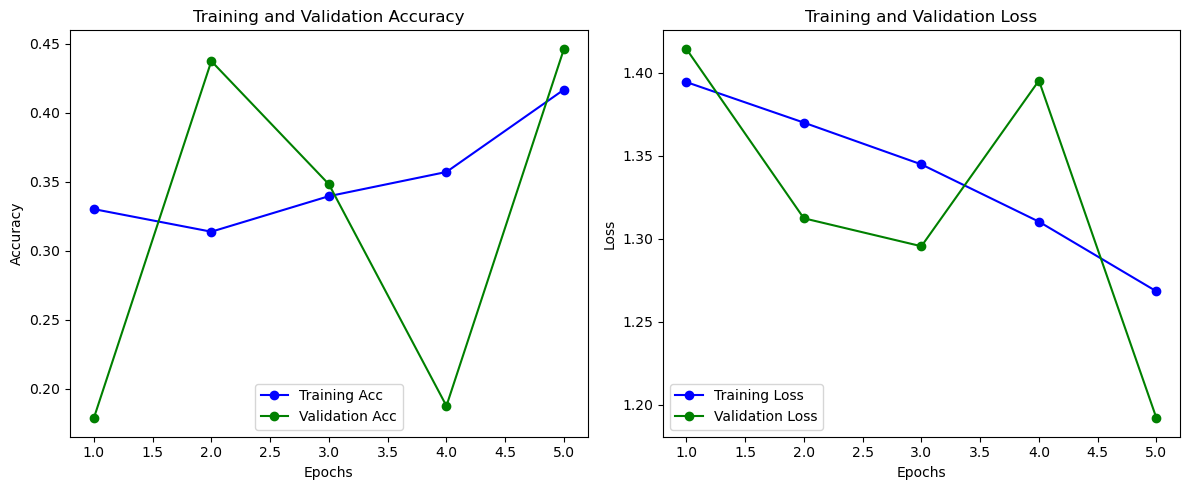

In [25]:
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'bo-', label='Training Acc')
    plt.plot(epochs, val_acc, 'go-', label='Validation Acc')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    #plt.xticks(epochs)
    plt.legend()

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'bo-', label='Training Loss')
    plt.plot(epochs, val_loss, 'go-', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    #plt.xticks(epochs)
    plt.legend()

    plt.tight_layout()
    plt.show()

# Call the function
plot_history(history)

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

print("Training Accuracy:", acc)
print("\n Validation Accuracy:", val_acc)
print("\n Training loss:", loss)
print("\n Validation loss:", val_loss)

# Model Testing

## Model evaluate output

In [47]:
test_loss, test_accuracy = model.evaluate(test_dataset_for_model)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.7344 - loss: 0.6165

2026-11-09 12:51:05.576143: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1717', 856 bytes spill stores, 720 bytes spill loads



3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 4s/step - accuracy: 0.6825 - loss: 0.6773
Test Loss: 0.6773
Test Accuracy: 0.6825


## Predictions

In [48]:
from sklearn.metrics import confusion_matrix
# Get predictions
y_pred = []
y_true = []

for imgs, labels in test_dataset_for_model:
    preds = model.predict(imgs, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

# Check the distribution of what the model is actually "thinking"
print(f"Unique predictions made by model: {np.unique(y_pred)}")
print(f"Frequency of each prediction: {np.bincount(y_pred)}")

2026-11-09 12:51:14.198838: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1698', 56 bytes spill stores, 56 bytes spill loads

2026-11-09 12:51:20.195104: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1698', 52 bytes spill stores, 52 bytes spill loads



Unique predictions made by model: [0 1 2 3]
Frequency of each prediction: [ 40 115  30   4]


## Confusion Matrix

True Positive (TP): Patient has the disease, and the test says "Yes."

False Positive (FP): Patient is healthy, but the test says "Yes" (a False Alarm).

True Negative (TN): Patient is healthy, and the test says "No."

False Negative (FN): Patient has the disease, but the test says "No" (a Miss).

Since we have 4 classes not just a true or false (2 class problem) our confusion matrix is larger, but we can still redefine it such that is a true or false problem, i.e true is grade 3 is predicted as grade 3, false is grade 3 is the sum of those predicted as grade 0,1,2

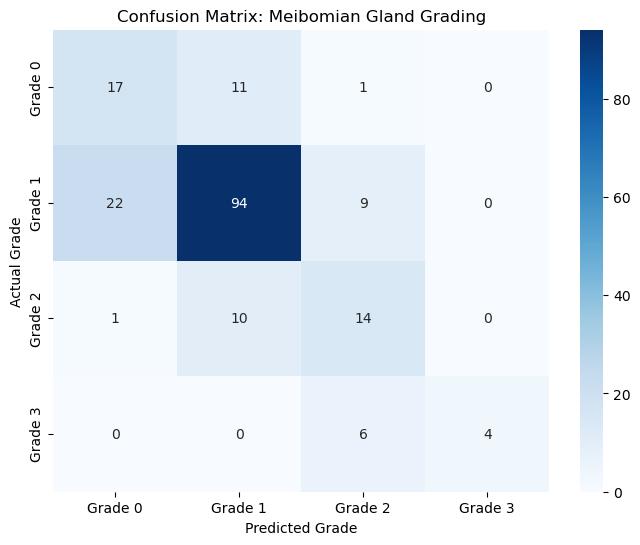

In [49]:
# 1. Get all true labels and model predictions
y_true = []
y_pred = []

for imgs, labels in test_dataset_for_model:
    preds = model.predict(imgs, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

# 2. Create the confusion matrix
cm = confusion_matrix(y_true, y_pred)
class_names = ['Grade 0', 'Grade 1', 'Grade 2', 'Grade 3']

# 3. Plot using Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title('Confusion Matrix: Meibomian Gland Grading')
plt.ylabel('Actual Grade')
plt.xlabel('Predicted Grade')
plt.show()

## Precision and recall
Precision (quality) asks: "Of all the times the model predicted 'Positive,' how often was it actually right?"

$$ Precision = \frac{TP}{TP+FP}$$

High Precision Example: A "Spam" filter. You’d rather see a few spam emails in your inbox (low recall) than have one important work email accidentally sent to the trash (low precision).

Recall (quantity) (also called Sensitivity) asks: "Of all the actual 'Positive' cases that exist, how many did the model find?"

$$ Recall = \frac{TP}{TP+FN}$$

High Recall Example: Cancer screening. It is much better to tell a healthy person they might be sick and need more tests (False Positive) than to tell a sick person they are perfectly fine (False Negative).

In [50]:
# Get arrays of scores for each class
precisions = precision_score(y_true, y_pred, average=None)
recalls = recall_score(y_true, y_pred, average=None)

for i in range(4):
    print(f"Class {i}: Precision = {precisions[i]:.4f}, Recall = {recalls[i]:.4f}")

Class 0: Precision = 0.4250, Recall = 0.5862
Class 1: Precision = 0.8174, Recall = 0.7520
Class 2: Precision = 0.4667, Recall = 0.5600
Class 3: Precision = 1.0000, Recall = 0.4000


In [51]:
# Define your class names for better readability
target_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3']

# Print the report
print(classification_report(y_true, y_pred, target_names=target_names))

              precision    recall  f1-score   support

     Class 0       0.42      0.59      0.49        29
     Class 1       0.82      0.75      0.78       125
     Class 2       0.47      0.56      0.51        25
     Class 3       1.00      0.40      0.57        10

    accuracy                           0.68       189
   macro avg       0.68      0.57      0.59       189
weighted avg       0.72      0.68      0.69       189



## Get actual predictions from model on test dataset

In [52]:
# List to store the final guesses
all_predictions = []
all_softmax_values = []  # store softmax probabilities

for imgs, labels in test_dataset_for_model:
    # 1. Get raw probabilities
    preds = model.predict(imgs, verbose=0)
    
    # 2. Pick the index with the highest probability (the actual score), for softmax we skip this step
    # axis=1 tells it to look horizontally across the 4 scores
    guesses = np.argmax(preds, axis=1)
    
    # 3. Add to our list
    all_predictions.extend(guesses)
    # For softmax values instead we take softmax probabilities from preds and append to our array(not its in batches so we used extend)
    all_softmax_values.extend(preds)

# Convert to a final NumPy array
final_prediction_array = np.array(all_predictions)

# Convert to a numpy array with shape (total_samples, 4)
final_softmax_array = np.array(all_softmax_values)

# Print the final result
print("Array of Model Predictions (Meiboscores):")
print(final_prediction_array)

Array of Model Predictions (Meiboscores):
[1 2 1 1 2 0 1 1 3 2 0 1 1 1 2 1 1 0 2 1 3 1 1 1 0 0 2 1 1 0 0 2 1 0 0 2 1
 0 0 0 1 1 2 1 1 1 1 1 1 1 1 1 1 0 1 3 0 2 1 1 1 0 0 0 0 1 2 1 0 1 1 1 0 1
 0 1 1 1 1 2 1 1 1 2 1 3 0 1 2 0 1 2 2 1 1 0 1 0 0 1 1 1 0 1 0 1 2 1 0 1 1
 0 0 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 1 2 1 2 1 0 1 2 1 1 1 1 1 2 2 1 1 1 1 2
 2 1 1 1 1 1 1 1 1 1 1 1 1 1 2 0 1 0 1 2 1 2 1 0 0 0 1 2 1 0 1 1 1 2 1 1 1
 1 1 1 1]


In [53]:
y_true = np.array(y_true).astype(int)
print(y_true)

[1 2 0 0 3 0 1 1 3 2 1 1 1 1 2 1 1 0 2 1 3 1 1 1 0 0 1 1 1 0 1 2 1 0 0 1 1
 0 1 0 2 1 3 1 1 1 1 0 1 1 0 1 2 1 1 3 0 2 1 1 1 0 0 1 1 1 1 1 0 1 2 1 0 1
 1 1 2 1 1 3 1 1 1 3 1 3 1 1 1 0 0 2 1 1 1 2 1 1 0 1 1 0 1 1 1 0 2 1 0 1 1
 1 1 1 1 1 1 2 1 1 2 1 1 0 1 1 1 1 2 2 1 2 1 1 1 1 1 0 1 1 1 1 2 1 1 1 1 3
 3 0 1 1 1 1 1 1 1 1 1 1 1 2 2 1 1 1 1 1 1 1 1 1 1 1 0 2 1 1 1 2 1 0 1 1 1
 1 2 2 1]


In [54]:
# Print the final softmax results
print("Array of Model Softmax Scores (Probabilities for each class):")
print(final_softmax_array)

Array of Model Softmax Scores (Probabilities for each class):
[[1.58009365e-01 4.77780104e-01 3.41293305e-01 2.29171887e-02]
 [3.47923022e-04 6.51859194e-02 9.30242300e-01 4.22387756e-03]
 [3.90292108e-01 5.66274643e-01 4.20292653e-02 1.40406622e-03]
 [2.23996252e-01 7.54827321e-01 2.10082568e-02 1.68220940e-04]
 [1.73467188e-03 5.63027449e-02 7.61264622e-01 1.80697963e-01]
 [7.53317773e-01 2.43214712e-01 3.11437831e-03 3.53079144e-04]
 [1.14092432e-01 8.00047040e-01 8.56456384e-02 2.14943255e-04]
 [2.20944747e-01 6.83149099e-01 9.51092988e-02 7.96755834e-04]
 [1.52697612e-04 2.04768963e-03 8.24815631e-02 9.15318072e-01]
 [2.42391558e-04 3.97478431e-01 6.02276444e-01 2.75286993e-06]
 [5.95551908e-01 4.00387377e-01 3.47310444e-03 5.87654649e-04]
 [2.96849106e-02 5.88937342e-01 3.79911363e-01 1.46632059e-03]
 [4.97827753e-02 8.32026303e-01 1.18075579e-01 1.15330367e-04]
 [3.92075107e-02 7.19650686e-01 2.39650607e-01 1.49126374e-03]
 [5.47583820e-03 2.66415358e-01 7.27738142e-01 3.7067470

In [55]:
with open("Details.txt", "a") as f:
    # Print the final result
    f.write(f"\n \n Array of Model Predictions softmax probabilities:\n {final_softmax_array.tolist()}")


# Save details to txt file

## Save general details and results

In [56]:
with open("Details.txt", "a") as f:
    # Print batch size and learning rate
    f.write("\n")
    f.write(f"batch_size : {batch_size}")
    f.write("\n")
    f.write(f"l_rate : {l_rate}")
    
    # Evaluate output
    f.write("\n")  # Adds a blank line to separate from previous data
    f.write("Model Evaluation Results:\n")
    f.write(f"Test Loss: {test_loss:.4f}\n")
    f.write(f"Test Accuracy: {test_accuracy:.4f}\n")

    # Unique predictions output
    f.write(f"Unique predictions made by model: {np.unique(y_pred)}\n")
    f.write(f"Frequency of each prediction: {np.bincount(y_pred)}\n")

    # Precision and recall
    for i in range(4):
        f.write(f"Class {i}: Precision = {precisions[i]:.4f}, Recall = {recalls[i]:.4f}\n")

    # Full classification_report
    f.write(classification_report(y_true, y_pred, target_names=target_names))

    # Training history arrays
    f.write(f"\n Training Accuracy: \n {acc}")
    f.write(f"\n Validation Accuracy: \n {val_acc}")
    f.write(f"\n Training loss: \n {loss}")
    f.write(f"\n Validation loss: \n {val_loss}")

    # Print the final result
    f.write(f"\n Array of Model Predictions (Meiboscores):\n {final_prediction_array.tolist()}")


## Save model details

In [57]:
with open("Details.txt", "a") as f:
    f.write(f"""\n

# 1. Load the ResNet50 base model
# include_top=False removes the final 1000-class ImageNet layer
# weights='imagenet' uses pre-trained weights to start with
# base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 448, 3))
# base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(320, 640, 3))
# base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))


base_model = ResNet50(weights= None, include_top=False, input_shape=(224, 448, 3))
#base_model = ResNet50(weights= None, include_top=False, input_shape=(320, 640, 3))


# 2. Build the base model using ResNet50V2
#base_model = ResNet50V2(weights=None, include_top=False, input_shape=(224, 448, 3))


# # 2. Inject L2 (Do this BEFORE compiling)
# l2_strength = 0.0001
# for layer in base_model.layers:
#     if hasattr(layer, 'kernel_regularizer'):
#         layer.kernel_regularizer = tf.keras.regularizers.l2(l2_strength)


# 2. Freeze the base model (Optional but recommended for the first few epochs)
# This prevents the pre-trained weights from being destroyed early on
#base_model.trainable = False 
base_model.trainable = True


#####################################################
# # 1. Unfreeze the very beginning to adapt to Image+Mask input
# for layer in base_model.layers:
#     if layer.name == 'conv1_conv':
#         layer.trainable = True

# #Unfreeze last 10 layers
# # 2. Freeze all layers except the last N layers
# # Let's say you want to unfreeze the last 10 layers
# fine_tune_at = -10 

# for layer in base_model.layers[fine_tune_at:]:   # everything is frozen except last few layers
#     layer.trainable = True

# # 3. Verify which layers are trainable
# for layer in base_model.layers:
#     print(f"{layer.name}: {layer.trainable}")
#####################################################

# IMPORTANT: Keep BatchNormalization frozen to prevent mean/variance collapse
# unless you have a very large batch size (>32)
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False


# 3. Build your custom head
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(), # Reduces the spatial dimensions
    layers.BatchNormalization(),      # Helps with training stability
    layers.Dropout(0.5),             # CRITICAL for your overfitting issue    # 0.5 originally drop to 0.2
    layers.Dense(256, activation='relu'),
    #layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.00001)),
    layers.Dropout(0.3),                                                             # 0.3 drop to 0.1
    layers.Dense(4, activation='softmax') # Your 4 grading classes
])

       
    """)

## Save Model best weights

In [58]:
# # This is safe because EarlyStopping already rolled the model back to the best version
# model.save_weights('best_model_weights.weights.h5')

In [59]:
# Save entire model as only saving weights would not work sometimes
model.save('my_complete_model.keras')

## Load Model best weights

In [281]:
# # Must create the model first! BUT NOT COMPILE  WE COMPILE AFTER LOADING

# # Load the weights
# model.load_weights('best_model_weights.weights.h5')

In [282]:
# When loading (No need to rebuild the Sequential layers manually!)
model = load_model('my_complete_model.keras')

# Validation loading and testing 

## Load and get results

In [38]:
## Load the model 
model = load_model('my_complete_model.keras')

# 1. Evaluate the model on the validation dataset
val_loss, val_accuracy = model.evaluate(val_dataset_for_model)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")

from sklearn.metrics import confusion_matrix
import numpy as np

# 2. Get predictions for the validation set
y_pred = []
y_true = []

for imgs, labels in val_dataset_for_model:
    preds = model.predict(imgs, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

# 3. Analyze the distribution of validation predictions
print(f"Unique predictions (Val): {np.unique(y_pred)}")
print(f"Frequency of each prediction (Val): {np.bincount(y_pred)}")

y_true_val_array = np.array(y_true)
print(y_true_val_array.tolist())

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.6696 - loss: 0.7755
Validation Loss: 0.7755
Validation Accuracy: 0.6696
Unique predictions (Val): [0 1 2 3]
Frequency of each prediction (Val): [24 58 25  5]
[0, 1, 2, 1, 0, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 2, 0, 2, 1, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 0, 2, 1, 2, 1, 0, 1, 0, 2, 1, 0, 0, 1, 1, 0, 1, 0, 2, 1, 0, 1, 2, 1, 1, 0, 1, 1, 3, 3, 1, 1, 1, 1, 2, 0, 1, 1, 2, 1, 0, 2, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 2, 0, 0, 0, 1, 1, 2, 3, 1, 0, 3, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1]


## Confusion matrix

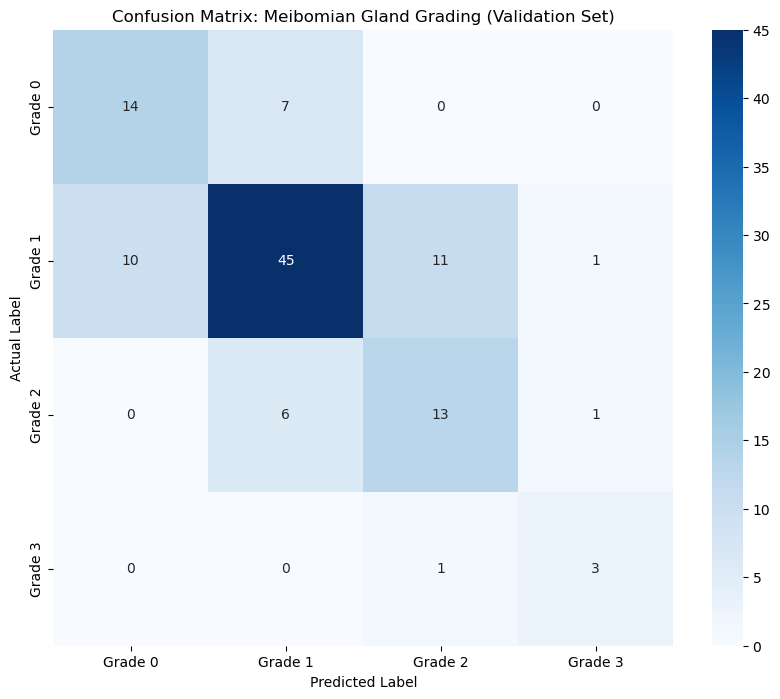

In [39]:
# Create the confusion matrix
cm = confusion_matrix(y_true, y_pred)
class_names = ['Grade 0', 'Grade 1', 'Grade 2', 'Grade 3']

# Plot using Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, 
            yticklabels=class_names)

plt.title('Confusion Matrix: Meibomian Gland Grading (Validation Set)')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

## Output meiboscore array and output softmax probabilities array

In [40]:
# List to store the final guesses for the Validation set
val_predictions = []
val_softmax_values = []  # store softmax probabilities

# Change: iterate through the validation dataset
for imgs, labels in val_dataset_for_model:
    # 1. Get raw probabilities
    preds = model.predict(imgs, verbose=0)
    
    # 2. Pick the index with the highest probability
    guesses = np.argmax(preds, axis=1)
    
    # 3. Add to our lists
    val_predictions.extend(guesses)
    val_softmax_values.extend(preds)

# Convert to final NumPy arrays
final_val_prediction_array = np.array(val_predictions)
final_val_softmax_array = np.array(val_softmax_values)

# Print the final result
print("Array of Validation Model Predictions (Meiboscores):")
print(final_val_prediction_array)

# Optional: Check shape to ensure it matches your validation sample count
print(f"Total Validation Samples Processed: {len(final_val_prediction_array)}")

Array of Validation Model Predictions (Meiboscores):
[0 1 2 2 0 2 1 1 1 1 1 1 1 1 0 2 1 0 2 0 2 1 1 1 1 1 2 0 1 2 1 1 0 2 1 2 1
 1 2 1 1 1 0 1 1 0 0 1 0 2 1 1 1 1 1 0 0 1 1 2 3 2 1 1 1 3 0 1 1 2 1 0 1 1
 0 2 1 0 1 0 2 1 2 3 2 1 1 1 2 0 0 1 2 1 2 3 1 0 3 1 1 2 1 0 2 1 0 0 1 2 1
 1]
Total Validation Samples Processed: 112


In [41]:
# Print the final softmax results
print("Array of Model Softmax Scores (Probabilities for each class):")
print(final_val_softmax_array)

Array of Model Softmax Scores (Probabilities for each class):
[[9.23821390e-01 7.53070191e-02 5.47270873e-04 3.24278342e-04]
 [5.51772006e-02 6.44825578e-01 2.99684137e-01 3.13127530e-04]
 [4.83512820e-04 3.50976288e-02 8.71254086e-01 9.31647941e-02]
 [1.60100963e-02 3.85726601e-01 5.67974210e-01 3.02890819e-02]
 [7.53121436e-01 2.36848414e-01 5.15785860e-03 4.87220474e-03]
 [7.91124839e-05 3.84897590e-02 9.59050357e-01 2.38085003e-03]
 [4.47008938e-01 5.42854249e-01 7.57597247e-03 2.56086234e-03]
 [5.79083264e-02 8.06260765e-01 1.34539679e-01 1.29122450e-03]
 [1.71969652e-01 6.54488921e-01 1.72007337e-01 1.53414556e-03]
 [3.05559523e-02 7.30713725e-01 2.22694650e-01 1.60356835e-02]
 [1.78915411e-01 5.72730720e-01 1.70969337e-01 7.73845166e-02]
 [5.13410345e-02 5.34985840e-01 3.43698442e-01 6.99746832e-02]
 [1.30180474e-02 5.05470991e-01 4.80937898e-01 5.73119207e-04]
 [1.56994641e-01 5.78998029e-01 2.57150859e-01 6.85647037e-03]
 [8.20379615e-01 1.51057854e-01 1.07985986e-02 1.7763903

## Save the arrays

In [42]:
with open("Validation arrays meiboscores and softmax.txt", "a") as f:
    # Print the final result
    f.write(f"\n Array of validation set true meiboscores (Meiboscores):\n {y_true_val_array.tolist()}")
    f.write(f"\n Array of validation set Model Predictions (Meiboscores):\n {final_val_prediction_array.tolist()}")
    f.write(f"\n \n Array of validation set Model Predictions softmax probabilities:\n {final_val_softmax_array.tolist()}")

In [43]:
# 2. Print a text report for precision, recall, and f1-score
print("Classification Report:")
report = (classification_report(y_true, y_pred))
print(report)

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.67      0.62        21
           1       0.78      0.67      0.72        67
           2       0.52      0.65      0.58        20
           3       0.60      0.75      0.67         4

    accuracy                           0.67       112
   macro avg       0.62      0.68      0.65       112
weighted avg       0.69      0.67      0.67       112



In [44]:
with open("Validation arrays meiboscores and softmax.txt", "a") as f:
    # Add the Classification Report
    f.write("\n\nClassification Report:\n")
    f.write(report)

# Extra training

In [36]:
# Phase 2: Unfreeze base for fine-tuning
base_model.trainable = True
# Use lower learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model.fit(
    train_dataset_for_model,
    validation_data=val_dataset_for_model,
    epochs=10,
    callbacks=[early_stop_12,  text_file_logger]
)

Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 44s 139ms/step - accuracy: 0.4641 - loss: 2.5420 - val_accuracy: 0.0357 - val_loss: 16.4501
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - accuracy: 0.7641 - loss: 0.8586 - val_accuracy: 0.1875 - val_loss: 5.9987
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 111ms/step - accuracy: 0.8703 - loss: 0.3467 - val_accuracy: 0.1875 - val_loss: 9.8153
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 111ms/step - accuracy: 0.9359 - loss: 0.2094 - val_accuracy: 0.1786 - val_loss: 9.8045
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - accuracy: 0.9391 - loss: 0.1986 - val_accuracy: 0.1875 - val_loss: 8.7845
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 113ms/step - accuracy: 0.9672 - loss: 0.0880 - val_accuracy: 0.3036 - val_loss: 6.4468
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 111ms/step - accuracy: 0.9563 - loss: 0.1354 - val_accuracy: 0.2946 - val_loss: 6.8215
Epoch 8/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 9s 111ms/step - accuracy: 0.9688 - loss: 0.0958 - val_accuracy: 

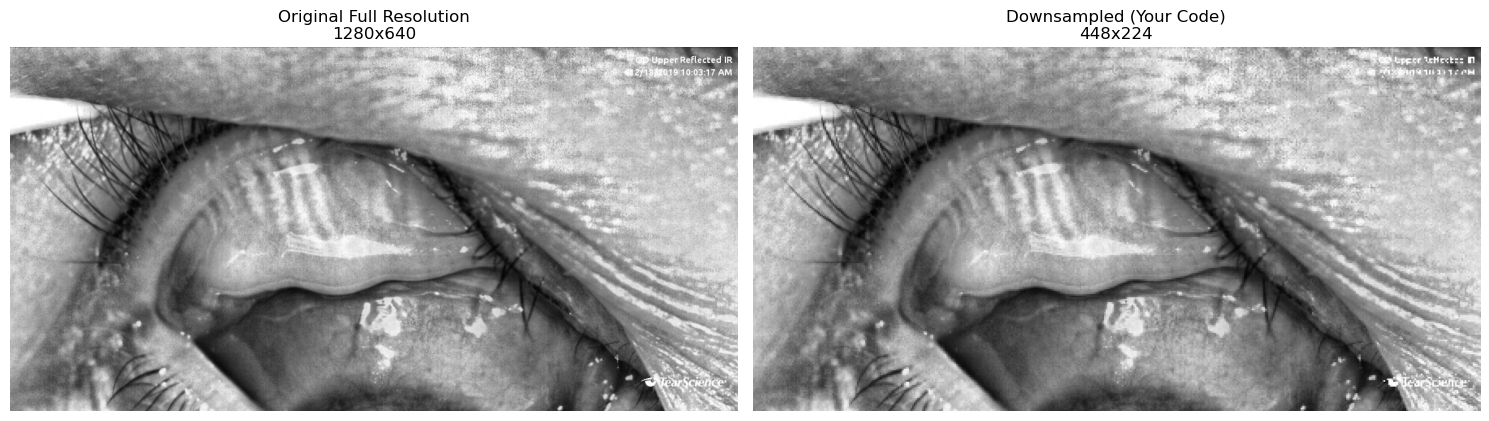

In [44]:
import matplotlib.pyplot as plt

def compare_resolutions(image_path, target_height=224, target_width=448):
    # 1. Load Original (Full Resolution)
    raw_img = tf.io.read_file(image_path)
    raw_img = tf.image.decode_jpeg(raw_img, channels=1)
    
    # 2. Load Resized (Your Preprocessed version)
    # Using 'nearest' as you did to avoid bilinear blurring of mask edges
    resized_img = tf.image.resize(raw_img, [target_height, target_width], method='nearest')
    
    # Plotting
    plt.figure(figsize=(15, 10))
    
    plt.subplot(1, 2, 1)
    plt.title(f"Original Full Resolution\n{raw_img.shape[1]}x{raw_img.shape[0]}")
    plt.imshow(tf.squeeze(raw_img), cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.title(f"Downsampled (Your Code)\n{target_width}x{target_height}")
    plt.imshow(tf.squeeze(resized_img), cmap='gray')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()

# Test with your first training path
compare_resolutions(train_file_paths[0])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0423853].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.1223654].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.005935841..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.03302913..1.0477601].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0794674].


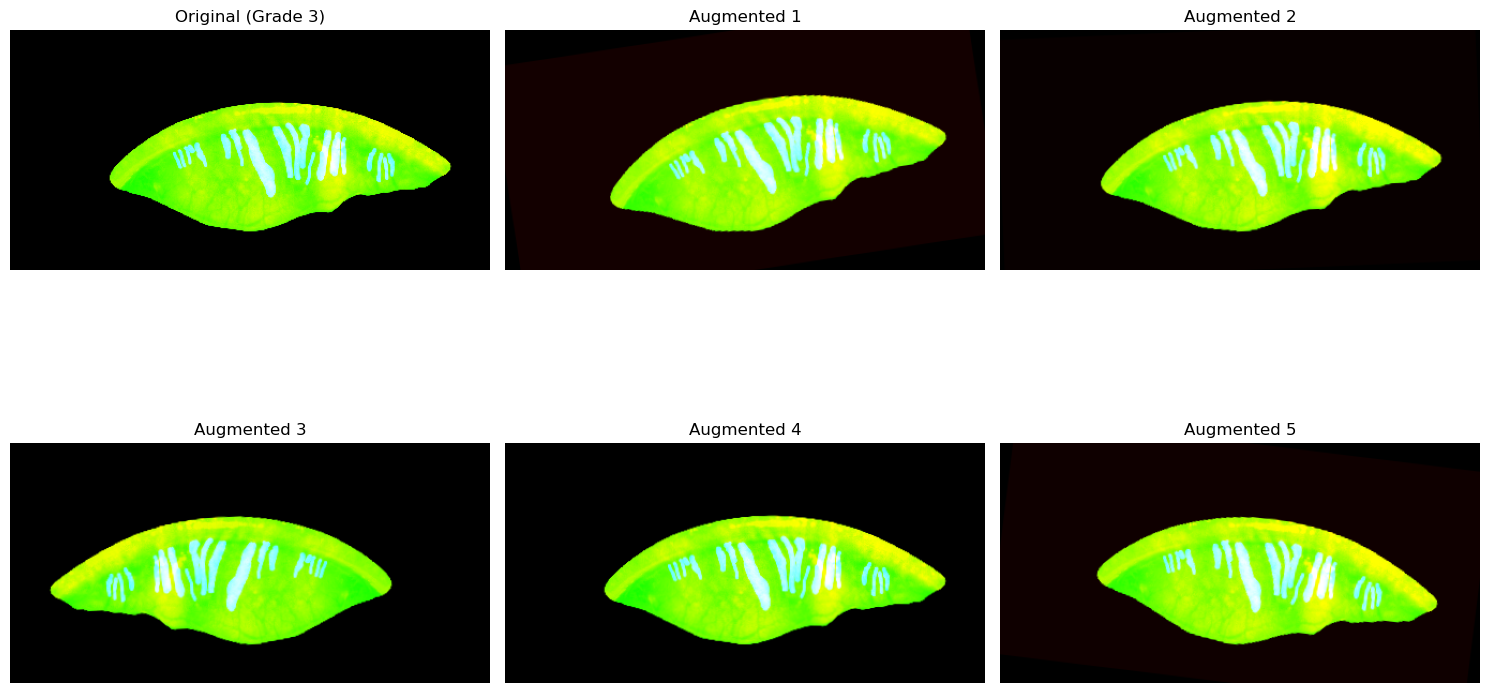

In [42]:
def visualize_augmentations(dataset, num_examples=1):
    # Take one batch from the dataset
    for images, labels in dataset.take(num_examples):
        plt.figure(figsize=(15, 10))
        
        # 1. Show Original
        plt.subplot(2, 3, 1)
        plt.imshow(images.numpy().squeeze(), cmap='gray')
        plt.title(f"Original (Grade {labels.numpy()})")
        plt.axis('off')
        
        # 2. Show 5 different augmented versions of that SAME image
        for i in range(5):
            # We call the function manually
            aug_img, _ = augment_image(images, labels)
            
            plt.subplot(2, 3, i + 2)
            plt.imshow(aug_img.numpy().squeeze(), cmap='gray')
            plt.title(f"Augmented {i+1}")
            plt.axis('off')
        plt.tight_layout()
        plt.show()

# Run it on your minority class dataset to see the Grade 3 samples
visualize_augmentations(val3_ds)

In [41]:
plt.imshow(display_img[:, :, 0], cmap='gray')

NameError: name 'display_img' is not defined

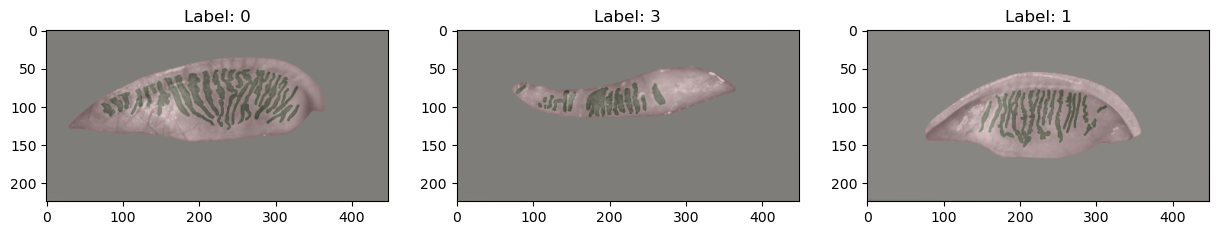

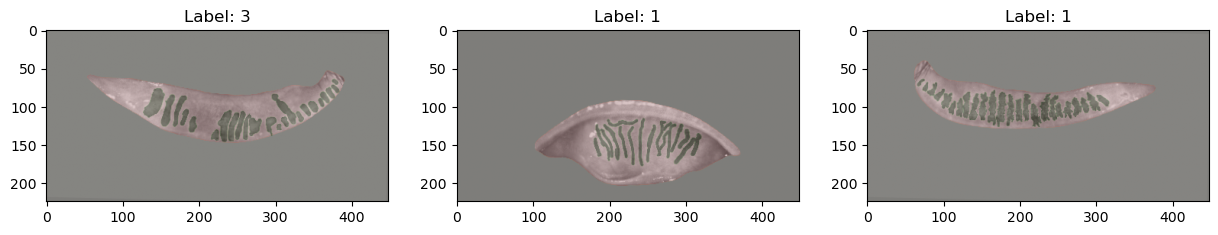

In [43]:
# Take one batch from your final pipeline
for images, labels in train_dataset_for_model.take(2):
    plt.figure(figsize=(15, 5))
    for i in range(3): # Show first 3 images in batch
        plt.subplot(1, 3, i+1)
        # Show Channel 0 (Raw Image)
        plt.imshow(images[i][:,:,0], cmap='gray') 
        # Overlay Channel 1 (Eyelid) in Red with alpha
        plt.imshow(images[i][:,:,1], alpha=0.3, cmap='Reds')
        # Overlay Channel 2 (Gland) in Green with alpha
        plt.imshow(images[i][:,:,2], alpha=0.3, cmap='Greens')
        plt.title(f"Label: {labels[i].numpy()}")
    plt.show()

2026-03-17 12:32:44.262903: W tensorflow/core/kernels/data/prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 67109120 bytes after encountering the first element of size 67109120 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.034664698..1.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.015199982..1.0464832].


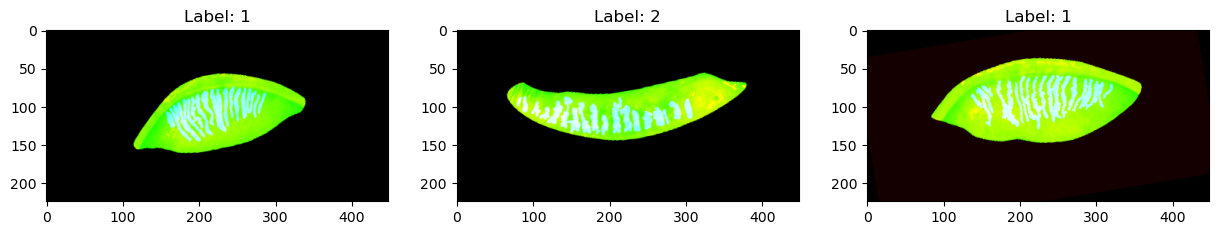

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0669885].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.073552].


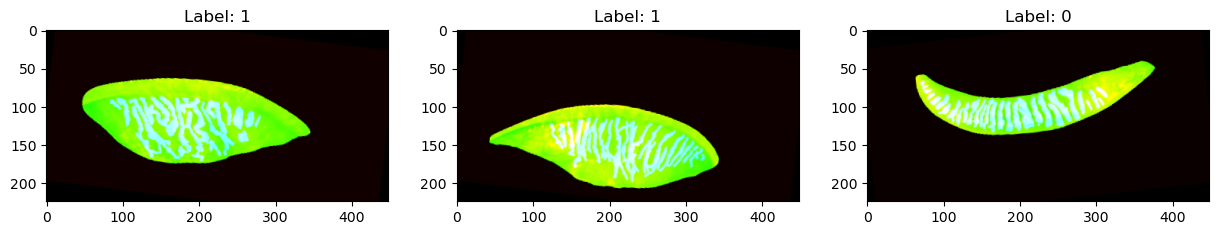

In [44]:
# Take one batch from your final pipeline
for images, labels in train_dataset_for_model.take(2):
    plt.figure(figsize=(15, 5))
    for i in range(3): # Show first 3 images in batch
        plt.subplot(1, 3, i+1)
        # Show Channel 0 (Raw Image)
        plt.imshow(images[i]) 
        plt.title(f"Label: {labels[i].numpy()}")
    plt.show()

In [49]:
import sys
import pandas as pd

def mem_report():
    # Get all global variables
    gl = globals()
    # Create a list of (name, size_in_mb)
    mem_usage = []
    for name, obj in gl.items():
        # Filter out built-in modules and functions
        if not name.startswith('_') and not callable(obj):
            try:
                # Convert bytes to MB
                size = sys.getsizeof(obj) / (1024**2)
                mem_usage.append((name, size))
            except:
                pass
    
    # Sort by size and display
    df_mem = pd.DataFrame(mem_usage, columns=['Variable', 'Size (MB)'])
    return df_mem.sort_values(by='Size (MB)', ascending=False).head(10)

print(mem_report())

                         Variable  Size (MB)
15                        main_df   0.144023
21                       train_df   0.121226
23               train_df_cleaned   0.113962
22                        test_df   0.030331
24                test_df_cleaned   0.028664
16                   test_only_df   0.016724
33   train_file_paths_gland_masks   0.005852
31               train_file_paths   0.005852
32  train_file_paths_eyelid_masks   0.005852
79                         y_pred   0.001671


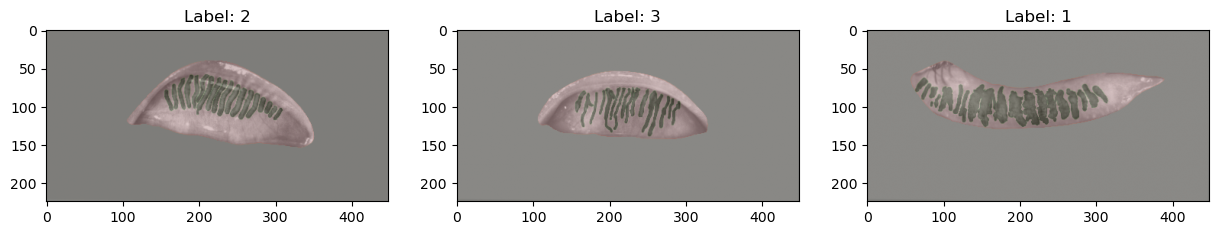

In [49]:
# Take one batch from your final pipeline
for images, labels in train_dataset_for_model.take(1):
    plt.figure(figsize=(15, 5))
    for i in range(3): # Show first 3 images in batch
        plt.subplot(1, 3, i+1)
        # Show Channel 0 (Raw Image)
        plt.imshow(images[i][:,:,0], cmap='gray') 
        # Overlay Channel 1 (Eyelid) in Red with alpha
        plt.imshow(images[i][:,:,1], alpha=0.3, cmap='Reds')
        # Overlay Channel 2 (Gland) in Green with alpha
        plt.imshow(images[i][:,:,2], alpha=0.3, cmap='Greens')
        plt.title(f"Label: {labels[i].numpy()}")
    plt.show()